# Cruce hardware × modelos (Gráfico 3)

Este notebook cruza los análisis de hardware y modelos para construir dos figuras del paper:

1. `fig03_hardware_model_perf_absolute.png` (valores absolutos)
2. `fig03_hardware_model_perf_percent.png` (porcentajes por combinación H×M)

## Definiciones usadas

- Hardware: perfiles `H1..H7` (etiqueta corta en eje X).
- Modelo: perfiles `M1..M5` según parámetros:
  - `M1`: `<1B`
  - `M2`: `1B–4B`
  - `M3`: `4B–8B`
  - `M4`: `8B–16B`
  - `M5`: `>16B`
- Categorías de performance por `avg_gen_tps`:
  - `Batch`: `<10`
  - `Interactivo mínimo`: `10–25`
  - `Interactivo fluido`: `>=25`

## Nota metodológica

Los porcentajes se calculan sobre corridas del dump limpio de LocalScore (no son proporciones poblacionales). Deben leerse considerando sesgos de cobertura y de runtime/cuantización reportados en la documentación metodológica.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

BASE = Path("..")
DATA_DIR = BASE / "data" / "processed"
FIG_DIR = BASE / "reports" / "figures"

HW_PATH_PREFERRED = DATA_DIR / "localscore_runs_labeled_H1-H7.csv"
HW_PATH_FALLBACK = DATA_DIR / "localscore_runs_labeled_H1-H6.csv"
MODEL_PATH = DATA_DIR / "localscore_models_solo_runs_enriched.csv"

OUT_TABLE_PATH = DATA_DIR / "fig03_hardware_model_perf_table.csv"
OUT_FIG_ABS = FIG_DIR / "fig03_hardware_model_perf_absolute.png"
OUT_FIG_PCT = FIG_DIR / "fig03_hardware_model_perf_percent.png"
OUT_FIG_ABS_SVG = FIG_DIR / "fig03_hardware_model_perf_absolute.svg"
OUT_FIG_PCT_SVG = FIG_DIR / "fig03_hardware_model_perf_percent.svg"
OUT_FIG_ABS_PDF = FIG_DIR / "fig03_hardware_model_perf_absolute.pdf"
OUT_FIG_PCT_PDF = FIG_DIR / "fig03_hardware_model_perf_percent.pdf"

H_ORDER = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
M_ORDER = ["M1", "M2", "M3", "M4", "M5"]
M_LABELS = {
    "M1": "<1B",
    "M2": "1-4B",
    "M3": "4-8B",
    "M4": "8-16B",
    "M5": ">16B",
}
M_HATCHES = {
    "M1": "",
    "M2": "//",
    "M3": "..",
    "M4": "xx",
    "M5": "\\\\",
}

PERF_ORDER = ["Batch", "Interactivo mínimo", "Interactivo fluido"]
PERF_COLORS = {
    "Batch": "#f4a261",
    "Interactivo mínimo": "#2a9d8f",
    "Interactivo fluido": "#1b7f3b",
}

MIN_TPS = 10.0
FLUENT_TPS = 25.0

PAPER_FONTS = {
    "title": 14,
    "label": 12,
    "tick": 10,
    "legend": 9,
    "note": 9,
}
LOW_N_THRESHOLD = 10

In [10]:
if HW_PATH_PREFERRED.exists():
    hw_path = HW_PATH_PREFERRED
else:
    hw_path = HW_PATH_FALLBACK

print(f"Hardware source: {hw_path}")
print(f"Models source:   {MODEL_PATH}")

hw = pd.read_csv(hw_path)
md = pd.read_csv(MODEL_PATH)

need_hw = {"benchmark_run_id", "profile_h", "avg_gen_tps"}
need_md = {"benchmark_run_id", "params"}

missing_hw = need_hw - set(hw.columns)
missing_md = need_md - set(md.columns)
if missing_hw:
    raise ValueError(f"Faltan columnas en dataset de hardware: {sorted(missing_hw)}")
if missing_md:
    raise ValueError(f"Faltan columnas en dataset de modelos: {sorted(missing_md)}")

runs = hw[["benchmark_run_id", "profile_h", "avg_gen_tps"]].merge(
    md[["benchmark_run_id", "params"]],
    on="benchmark_run_id",
    how="inner",
    validate="one_to_one",
)

print("Shape merged:", runs.shape)
runs.head(3)

Hardware source: ../data/processed/localscore_runs_labeled_H1-H6.csv
Models source:   ../data/processed/localscore_models_solo_runs_enriched.csv
Shape merged: (1556, 4)


,benchmark_run_id,profile_h,avg_gen_tps,params
0,1,H6_GPU_HIGH,103.101197,8030263296
1,2,H6_GPU_HIGH,59.943200,14770033664
2,3,H6_GPU_HIGH,330.012790,1498483200


In [11]:
def short_h(profile_h: str) -> str:
    if pd.isna(profile_h):
        return "UNKNOWN"
    p = str(profile_h)
    if p.startswith("H") and "_" in p:
        return p.split("_", 1)[0]
    if p in H_ORDER:
        return p
    return "UNKNOWN"


def profile_m(params):
    if pd.isna(params):
        return "UNKNOWN"
    p = float(params)
    if p < 1e9:
        return "M1"
    if p < 4e9:
        return "M2"
    if p < 8e9:
        return "M3"
    if p < 16e9:
        return "M4"
    return "M5"


def perf_category(avg_gen_tps):
    x = pd.to_numeric(avg_gen_tps, errors="coerce")
    # Sin categoría "No corrió": los nulos/invalidos se excluyen del análisis
    if pd.isna(x):
        return np.nan
    if x < MIN_TPS:
        return "Batch"
    if x < FLUENT_TPS:
        return "Interactivo mínimo"
    return "Interactivo fluido"

runs["H"] = runs["profile_h"].apply(short_h)
runs["M"] = runs["params"].apply(profile_m)
runs["perf_category"] = runs["avg_gen_tps"].apply(perf_category)

# filtros finales definidos para la figura
plot_runs = runs[
    runs["H"].isin(H_ORDER)
    & runs["M"].isin(M_ORDER)
    & runs["perf_category"].isin(PERF_ORDER)
].copy()

print("Corridas totales mergeadas:", len(runs))
print("Corridas usadas en figura:", len(plot_runs))
print("Cobertura H:\n", plot_runs["H"].value_counts().reindex(H_ORDER, fill_value=0))
print("Cobertura M:\n", plot_runs["M"].value_counts().reindex(M_ORDER, fill_value=0))

Corridas totales mergeadas: 1556
Corridas usadas en figura: 1550
Cobertura H:
 H
H1     51
H2    129
H3    440
H4     70
H5    440
H6    375
H7     45
Name: count, dtype: int64
Cobertura M:
 M
M1     27
M2    743
M3     57
M4    695
M5     28
Name: count, dtype: int64


In [12]:
agg = (
    plot_runs.groupby(["H", "M", "perf_category"], dropna=False)
    .size()
    .rename("n_runs")
    .reset_index()
)

full_idx = pd.MultiIndex.from_product(
    [H_ORDER, M_ORDER, PERF_ORDER], names=["H", "M", "perf_category"]
)
agg = (
    agg.set_index(["H", "M", "perf_category"])
    .reindex(full_idx, fill_value=0)
    .reset_index()
)

# tabla ancha para facilitar plot grouped+stacked
wide_abs = agg.pivot_table(
    index=["H", "M"],
    columns="perf_category",
    values="n_runs",
    fill_value=0,
).reindex(columns=PERF_ORDER)

totals = wide_abs.sum(axis=1)
wide_pct = wide_abs.div(totals.replace(0, np.nan), axis=0).fillna(0.0) * 100.0

display(agg.head(10))
print("Filas tabla agregada:", len(agg))
print("Combinaciones H×M:", wide_abs.shape[0])

,H,M,perf_category,n_runs
0,H1,M1,Batch,7
1,H1,M1,Interactivo mínimo,3
2,H1,M1,Interactivo fluido,1
3,H1,M2,Batch,19
4,H1,M2,Interactivo mínimo,13
5,H1,M2,Interactivo fluido,4
6,H1,M3,Batch,0
7,H1,M3,Interactivo mínimo,0
8,H1,M3,Interactivo fluido,0
9,H1,M4,Batch,4


Filas tabla agregada: 105
Combinaciones H×M: 35


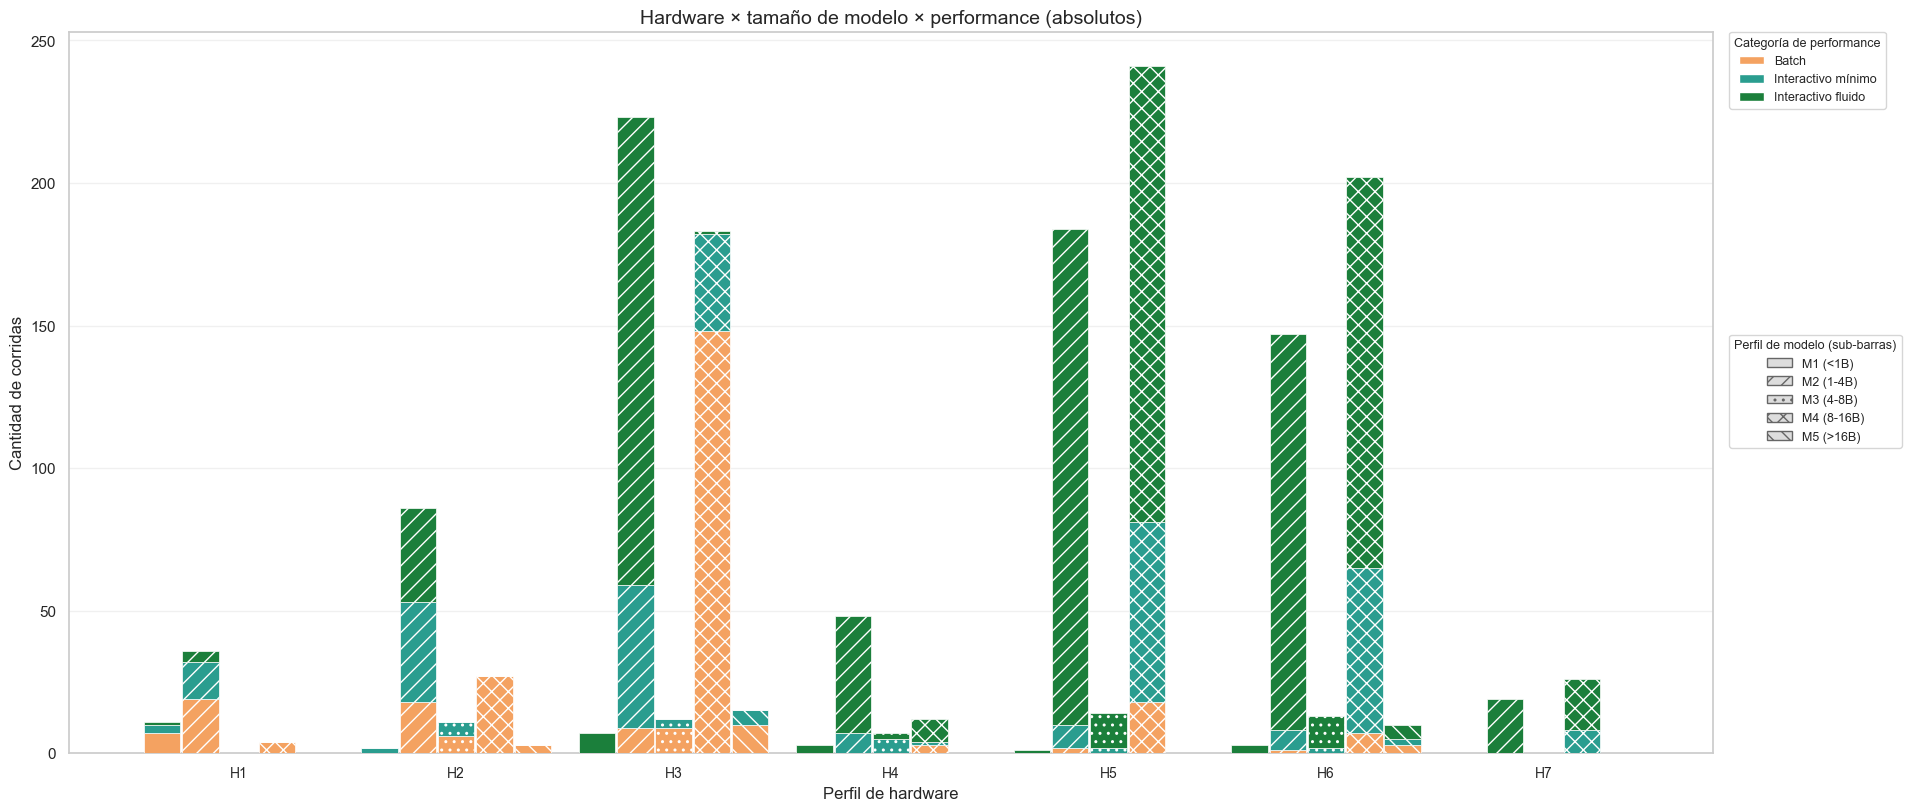

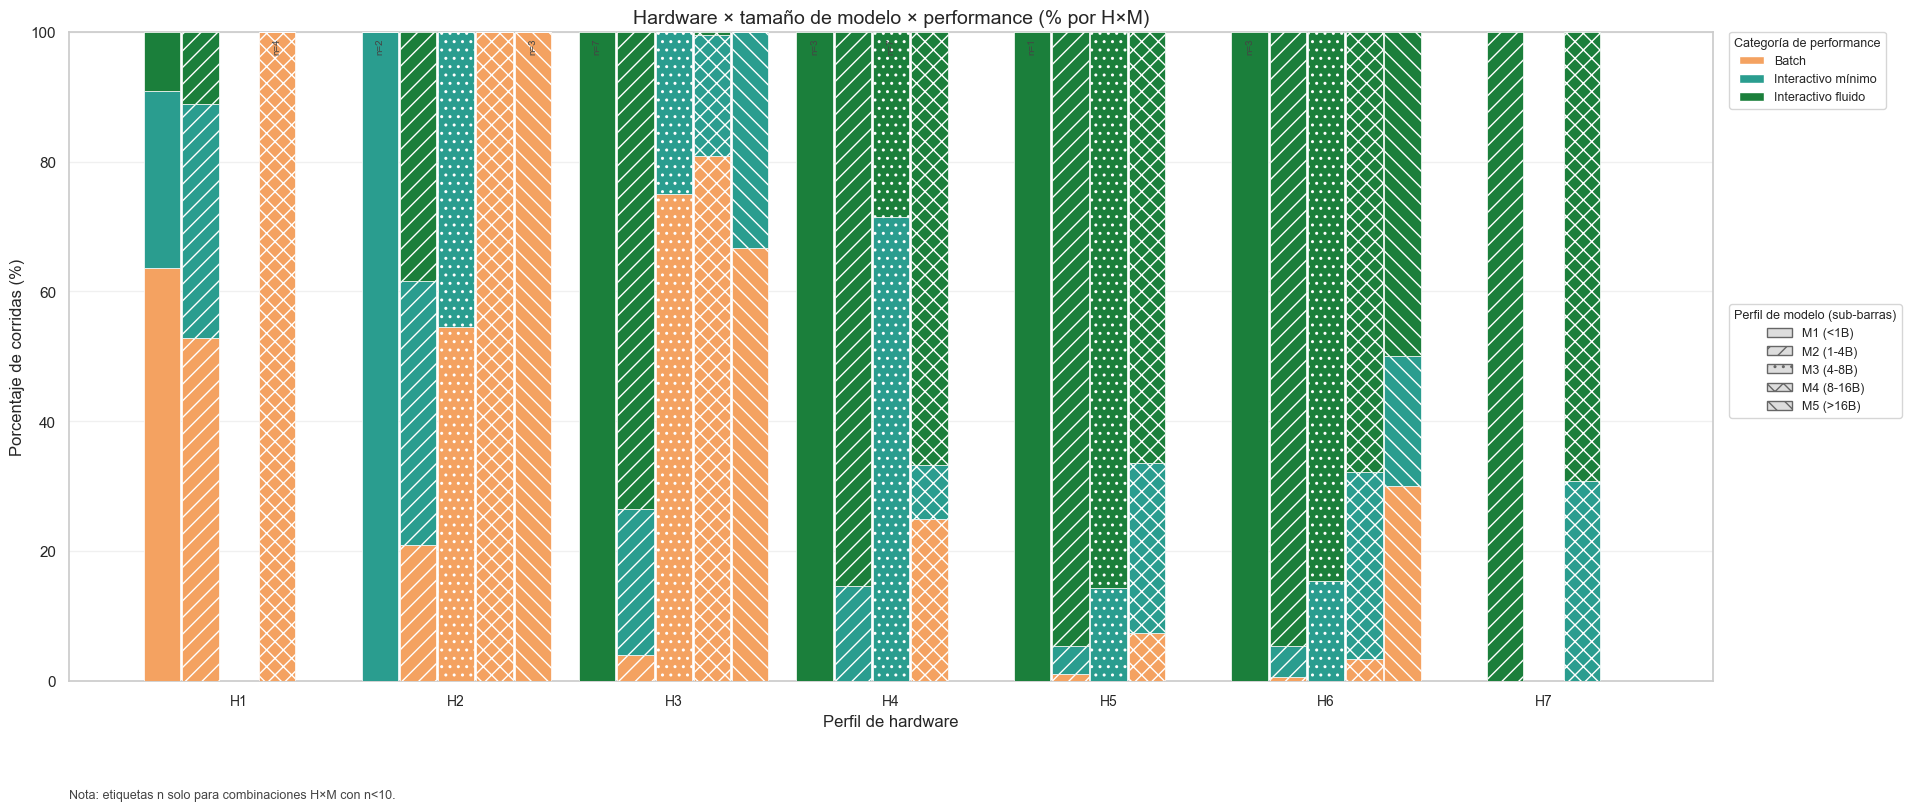

Figura absoluta PNG: ../reports/figures/fig03_hardware_model_perf_absolute.png
Figura porcentual PNG: ../reports/figures/fig03_hardware_model_perf_percent.png
Figura absoluta SVG: ../reports/figures/fig03_hardware_model_perf_absolute.svg
Figura porcentual SVG: ../reports/figures/fig03_hardware_model_perf_percent.svg
Figura absoluta PDF: ../reports/figures/fig03_hardware_model_perf_absolute.pdf
Figura porcentual PDF: ../reports/figures/fig03_hardware_model_perf_percent.pdf


In [13]:
def plot_grouped_stacked(
    wide_df,
    title,
    ylabel,
    out_png,
    out_svg,
    out_pdf,
    is_percent=False,
    totals_by_hm=None,
):
    x = np.arange(len(H_ORDER))
    n_m = len(M_ORDER)
    group_width = 0.88
    bar_w = group_width / n_m
    offsets = (np.arange(n_m) - (n_m - 1) / 2.0) * bar_w

    fig, ax = plt.subplots(figsize=(19, 8), constrained_layout=True)

    for i, m in enumerate(M_ORDER):
        sub = wide_df.xs(m, level="M").reindex(H_ORDER, fill_value=0)
        bottom = np.zeros(len(H_ORDER), dtype=float)

        for cat in PERF_ORDER:
            vals = sub[cat].to_numpy(dtype=float)
            ax.bar(
                x + offsets[i],
                vals,
                width=bar_w * 0.95,
                bottom=bottom,
                color=PERF_COLORS[cat],
                edgecolor="white",
                linewidth=0.5,
                hatch=M_HATCHES[m],
                label=cat if i == 0 else None,
                zorder=3,
            )
            bottom += vals

        # En porcentaje, marcar solo barras con baja muestra para no sobrecargar la figura.
        if is_percent and totals_by_hm is not None:
            hm_counts = totals_by_hm.xs(m, level="M").reindex(H_ORDER, fill_value=0).to_numpy(dtype=int)
            for j, n in enumerate(hm_counts):
                if 0 < n < LOW_N_THRESHOLD:
                    ax.text(
                        x[j] + offsets[i],
                        99.0,
                        f"n={n}",
                        ha="center",
                        va="top",
                        fontsize=7,
                        rotation=90,
                        color="#444444",
                    )

    ax.set_xticks(x)
    ax.set_xticklabels(H_ORDER, fontsize=PAPER_FONTS["tick"])
    ax.set_ylabel(ylabel, fontsize=PAPER_FONTS["label"])
    ax.set_xlabel("Perfil de hardware", fontsize=PAPER_FONTS["label"])
    ax.set_title(title, fontsize=PAPER_FONTS["title"])

    ax.grid(axis="y", alpha=0.28, zorder=0)
    ax.grid(axis="x", visible=False)

    if is_percent:
        ax.set_ylim(0, 100)
        ax.set_yticks(np.arange(0, 101, 20))
        ax.text(
            0.0,
            -0.18,
            f"Nota: etiquetas n solo para combinaciones H×M con n<{LOW_N_THRESHOLD}.",
            transform=ax.transAxes,
            fontsize=PAPER_FONTS["note"],
            color="#444444",
        )

    perf_handles = [Patch(facecolor=PERF_COLORS[c], edgecolor="white", label=c) for c in PERF_ORDER]
    m_handles = [Patch(facecolor="#dddddd", edgecolor="#666666", hatch=M_HATCHES[m], label=f"{m} ({M_LABELS[m]})") for m in M_ORDER]

    leg1 = ax.legend(
        handles=perf_handles,
        title="Categoría de performance",
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        borderaxespad=0.0,
        fontsize=PAPER_FONTS["legend"],
        title_fontsize=PAPER_FONTS["legend"],
    )
    ax.add_artist(leg1)
    ax.legend(
        handles=m_handles,
        title="Perfil de modelo (sub-barras)",
        loc="upper left",
        bbox_to_anchor=(1.01, 0.58),
        borderaxespad=0.0,
        fontsize=PAPER_FONTS["legend"],
        title_fontsize=PAPER_FONTS["legend"],
    )

    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    fig.savefig(out_svg, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    plt.show()


plot_grouped_stacked(
    wide_abs,
    "Hardware × tamaño de modelo × performance (absolutos)",
    "Cantidad de corridas",
    OUT_FIG_ABS,
    OUT_FIG_ABS_SVG,
    OUT_FIG_ABS_PDF,
    is_percent=False,
)

plot_grouped_stacked(
    wide_pct,
    "Hardware × tamaño de modelo × performance (% por H×M)",
    "Porcentaje de corridas (%)",
    OUT_FIG_PCT,
    OUT_FIG_PCT_SVG,
    OUT_FIG_PCT_PDF,
    is_percent=True,
    totals_by_hm=wide_abs.sum(axis=1),
)

print("Figura absoluta PNG:", OUT_FIG_ABS)
print("Figura porcentual PNG:", OUT_FIG_PCT)
print("Figura absoluta SVG:", OUT_FIG_ABS_SVG)
print("Figura porcentual SVG:", OUT_FIG_PCT_SVG)
print("Figura absoluta PDF:", OUT_FIG_ABS_PDF)
print("Figura porcentual PDF:", OUT_FIG_PCT_PDF)

In [14]:
out_table = agg.copy()
out_table["pct_within_HM"] = (
    out_table["n_runs"]
    / out_table.groupby(["H", "M"])["n_runs"].transform("sum").replace(0, np.nan)
    * 100.0
).fillna(0.0)

out_table.to_csv(OUT_TABLE_PATH, index=False)
print("Tabla exportada:", OUT_TABLE_PATH)
out_table.head(10)

Tabla exportada: ../data/processed/fig03_hardware_model_perf_table.csv


,H,M,perf_category,n_runs,pct_within_HM
0,H1,M1,Batch,7,63.636364
1,H1,M1,Interactivo mínimo,3,27.272727
2,H1,M1,Interactivo fluido,1,9.090909
3,H1,M2,Batch,19,52.777778
4,H1,M2,Interactivo mínimo,13,36.111111
5,H1,M2,Interactivo fluido,4,11.111111
6,H1,M3,Batch,0,0.000000
7,H1,M3,Interactivo mínimo,0,0.000000
8,H1,M3,Interactivo fluido,0,0.000000
9,H1,M4,Batch,4,100.000000


In [15]:
# Validaciones de consistencia
present_h = sorted(plot_runs["H"].dropna().unique().tolist())
present_m = sorted(plot_runs["M"].dropna().unique().tolist())

print("H presentes:", present_h)
print("M presentes:", present_m)

assert set(plot_runs["perf_category"].dropna().unique()) == set(PERF_ORDER), "Categorías de performance inesperadas"
assert "No corrió" not in set(plot_runs["perf_category"].dropna().unique()), "Apareció No corrió"

hm_totals = wide_abs.sum(axis=1)
pct_check = wide_pct.sum(axis=1).round(6)
mask_nonzero = hm_totals > 0
max_dev_nonzero = (pct_check[mask_nonzero] - 100.0).abs().max() if mask_nonzero.any() else 0.0
print("Desvío máximo (solo H×M con corridas) vs 100:", max_dev_nonzero)

if (~mask_nonzero).any():
    print("Aviso: hay combinaciones H×M sin corridas (en porcentaje quedan en 0).")

assert OUT_FIG_ABS.exists(), "No se generó la figura absoluta"
assert OUT_FIG_PCT.exists(), "No se generó la figura porcentual"
assert OUT_TABLE_PATH.exists(), "No se exportó la tabla agregada"

print("OK: salidas y checks validados.")

H presentes: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6', 'H7']
M presentes: ['M1', 'M2', 'M3', 'M4', 'M5']
Desvío máximo (solo H×M con corridas) vs 100: 0.0
Aviso: hay combinaciones H×M sin corridas (en porcentaje quedan en 0).
OK: salidas y checks validados.


In [ ]:
# Figura alternativa para paper corto: heatmap H×M (% interactivo fluido)
# - Eje X: M1..M5
# - Eje Y: H1..H7
# - Color: % interactivo fluido dentro de cada celda H×M
# - Texto en celda: n de corridas (n=...)
# - Celdas sin datos: gris claro
# - Celdas con n<10: marca *

OUT_FIG_HEAT_FLUENT_PNG = FIG_DIR / "fig03_hardware_model_perf_heatmap_fluido.png"
OUT_FIG_HEAT_FLUENT_SVG = FIG_DIR / "fig03_hardware_model_perf_heatmap_fluido.svg"
OUT_FIG_HEAT_FLUENT_PDF = FIG_DIR / "fig03_hardware_model_perf_heatmap_fluido.pdf"

# Usar out_table si existe en memoria; si no, leer CSV exportado previamente
if "out_table" in globals():
    hm_table = out_table.copy()
else:
    hm_table = pd.read_csv(OUT_TABLE_PATH)

# Totales por celda H×M (n)
hm_n = (
    hm_table.groupby(["H", "M"], as_index=False)["n_runs"]
    .sum()
    .rename(columns={"n_runs": "n_total"})
)

# % interactivo fluido por celda H×M
hm_fluent = (
    hm_table.loc[hm_table["perf_category"] == "Interactivo fluido", ["H", "M", "pct_within_HM"]]
    .rename(columns={"pct_within_HM": "pct_fluent"})
)

hm_plot = hm_n.merge(hm_fluent, on=["H", "M"], how="left")

# Asegurar orden
hm_plot["H"] = pd.Categorical(hm_plot["H"], categories=H_ORDER, ordered=True)
hm_plot["M"] = pd.Categorical(hm_plot["M"], categories=M_ORDER, ordered=True)
hm_plot = hm_plot.sort_values(["H", "M"])

# Matrices para heatmap y anotaciones
heat = hm_plot.pivot(index="H", columns="M", values="pct_fluent").reindex(index=H_ORDER, columns=M_ORDER)
counts = hm_plot.pivot(index="H", columns="M", values="n_total").reindex(index=H_ORDER, columns=M_ORDER)

# Celdas sin corridas -> NaN para pintarlas gris
heat = heat.where(counts > 0, np.nan)

# Texto por celda: n=... y * para n<10
annot = counts.copy().astype("float")
for h in H_ORDER:
    for m in M_ORDER:
        n = counts.loc[h, m]
        if pd.isna(n) or n == 0:
            annot.loc[h, m] = np.nan
        else:
            mark = "*" if n < LOW_N_THRESHOLD else ""
            annot.loc[h, m] = f"n={int(n)}{mark}"

# Colormap con gris para NaN
cmap = sns.light_palette("#1b7f3b", as_cmap=True)
cmap.set_bad("#e6e6e6")

fig, ax = plt.subplots(figsize=(8.2, 4.8), dpi=220)

sns.heatmap(
    heat,
    cmap=cmap,
    vmin=0,
    vmax=100,
    linewidths=0.7,
    linecolor="#ffffff",
    annot=annot,
    fmt="",
    annot_kws={"fontsize": 8, "color": "#1a1a1a"},
    cbar_kws={"label": "% interactivo fluido"},
    ax=ax,
)

ax.set_title("Hardware × tamaño de modelo: % interactivo fluido (por H×M)", fontsize=12)
ax.set_xlabel("Perfil de modelo (M)", fontsize=10)
ax.set_ylabel("Perfil de hardware (H)", fontsize=10)
ax.tick_params(axis="x", labelrotation=0, labelsize=9)
ax.tick_params(axis="y", labelrotation=0, labelsize=9)

# Etiquetas de M con rango
ax.set_xticklabels([f"{m}\n({M_LABELS[m]})" for m in M_ORDER])

fig.text(
    0.01,
    0.01,
    f"Nota: celdas sin corridas se muestran en gris. '*' indica n<{LOW_N_THRESHOLD}.",
    fontsize=8,
)

fig.tight_layout(rect=[0, 0.03, 1, 1])

fig.savefig(OUT_FIG_HEAT_FLUENT_PNG, bbox_inches="tight")
fig.savefig(OUT_FIG_HEAT_FLUENT_SVG, bbox_inches="tight")
fig.savefig(OUT_FIG_HEAT_FLUENT_PDF, bbox_inches="tight")
plt.close(fig)

print("Figura exportada:", OUT_FIG_HEAT_FLUENT_PNG)
print("Figura exportada:", OUT_FIG_HEAT_FLUENT_SVG)
print("Figura exportada:", OUT_FIG_HEAT_FLUENT_PDF)

heat

TypeError: Invalid value 'n=11' for dtype 'float64'

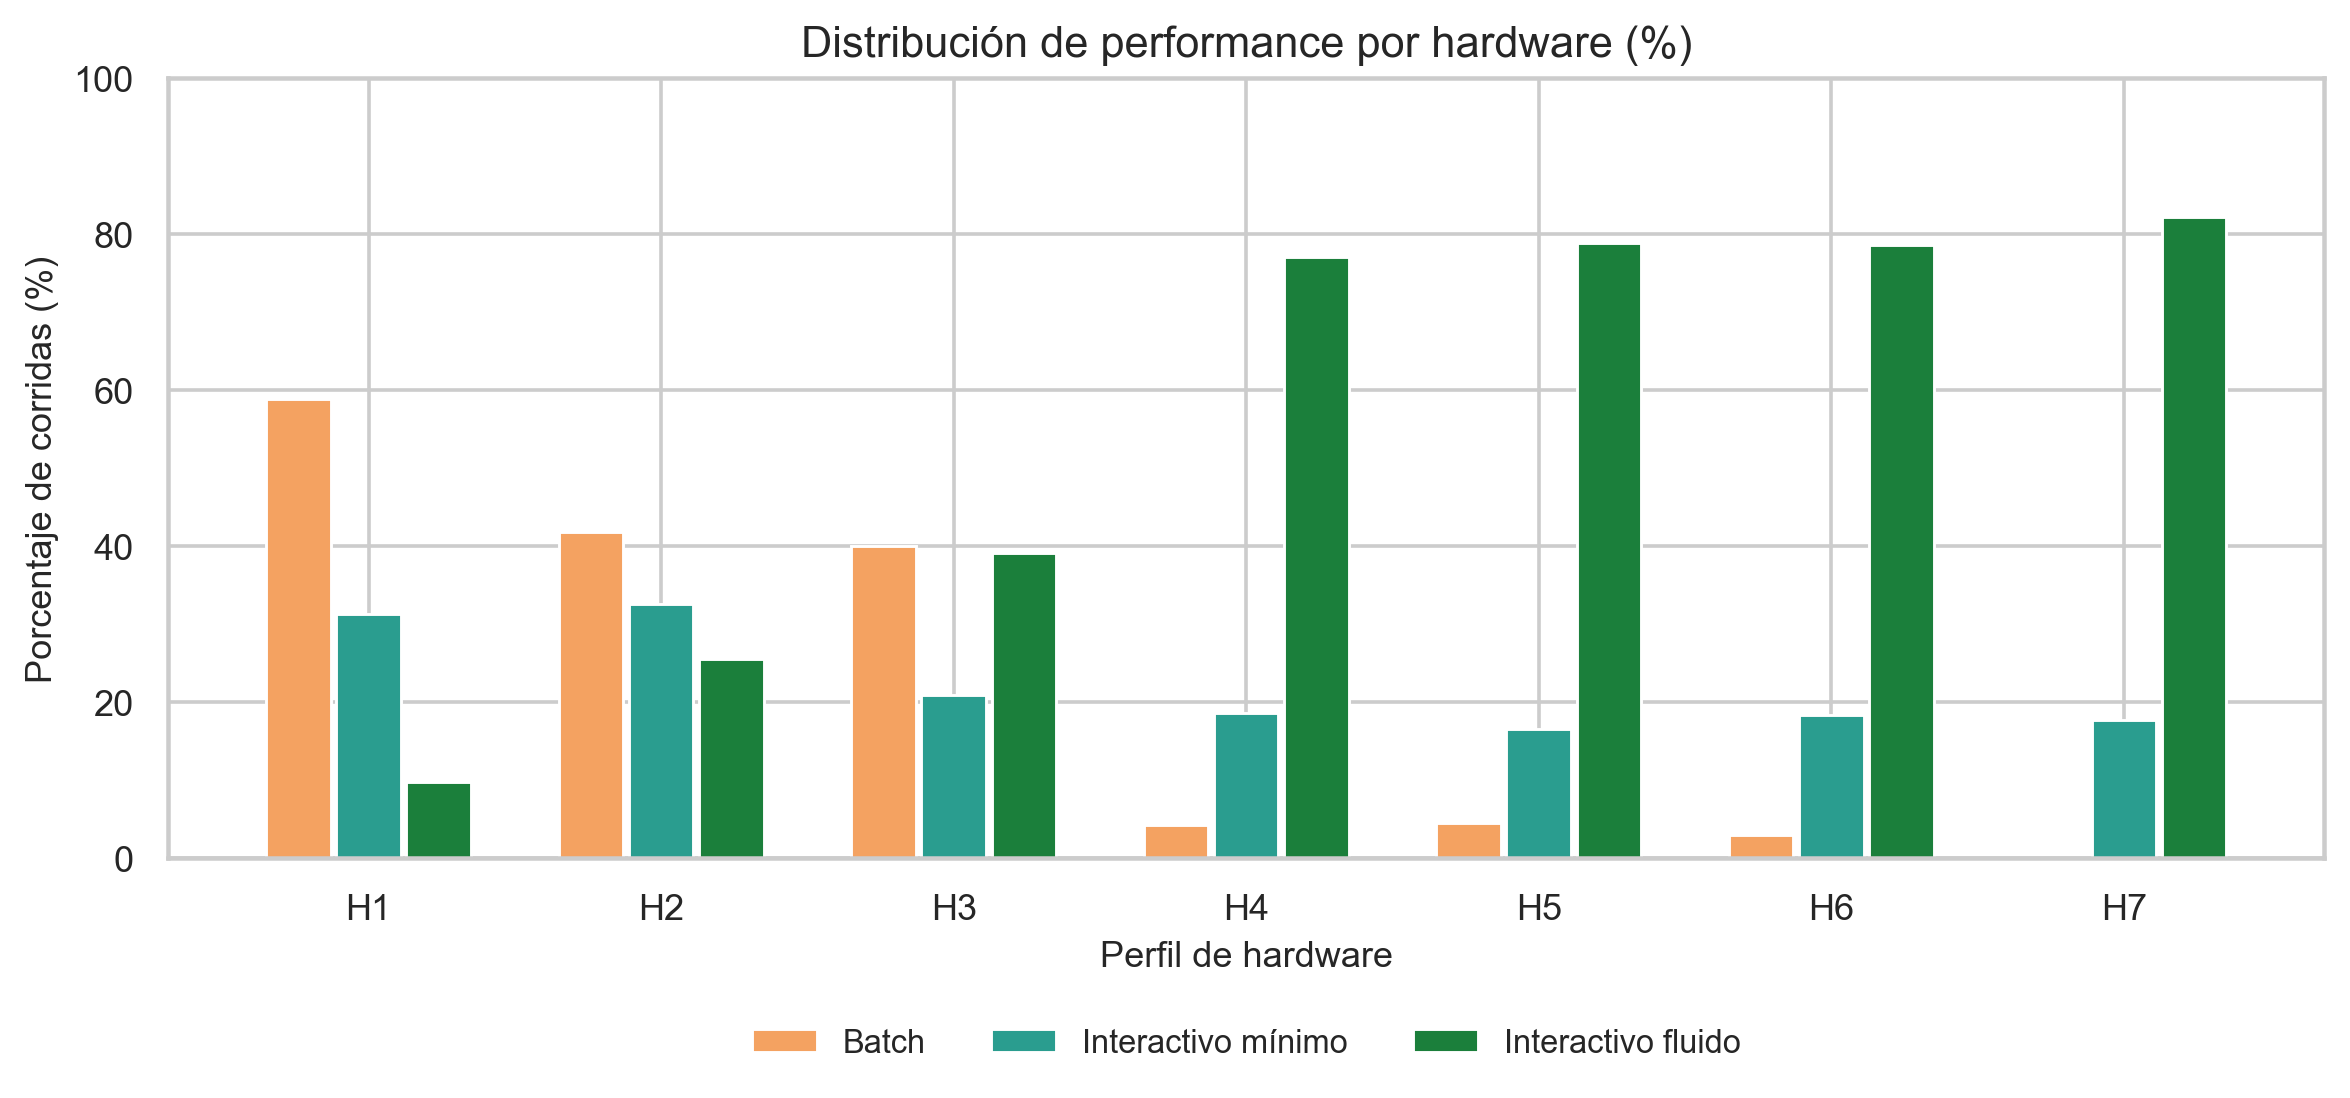

Figura simple PNG: ../reports/figures/fig03_hardware_perf_percent_simple.png
Figura simple SVG: ../reports/figures/fig03_hardware_perf_percent_simple.svg
Figura simple PDF: ../reports/figures/fig03_hardware_perf_percent_simple.pdf


In [ ]:
# Variante rápida del gráfico actual (paper corto)
# - Sin tramas (hatch)
# - 3 barras por H (Batch / Interactivo mínimo / Interactivo fluido)
# - Leyenda abajo en una línea
# - Tipografía mayor y márgenes recortados

OUT_FIG_PCT_SIMPLE = FIG_DIR / "fig03_hardware_perf_percent_simple.png"
OUT_FIG_PCT_SIMPLE_SVG = FIG_DIR / "fig03_hardware_perf_percent_simple.svg"
OUT_FIG_PCT_SIMPLE_PDF = FIG_DIR / "fig03_hardware_perf_percent_simple.pdf"

# Distribución por hardware (normalizada dentro de cada H)
h_perf = (
    plot_runs.groupby(["H", "perf_category"], as_index=False)
    .size()
    .rename(columns={"size": "n_runs"})
)

# Completar combinaciones faltantes H x categoría
h_perf = (
    h_perf.set_index(["H", "perf_category"])
    .reindex(pd.MultiIndex.from_product([H_ORDER, PERF_ORDER], names=["H", "perf_category"]))
    .fillna(0)
    .reset_index()
)

h_perf["pct_within_H"] = (
    h_perf["n_runs"]
    / h_perf.groupby("H")["n_runs"].transform("sum").replace(0, np.nan)
    * 100.0
).fillna(0.0)

x = np.arange(len(H_ORDER))
bar_w = 0.24
offsets = {
    "Batch": -bar_w,
    "Interactivo mínimo": 0.0,
    "Interactivo fluido": bar_w,
}

fig, ax = plt.subplots(figsize=(9.2, 4.8), dpi=260)

for cat in PERF_ORDER:
    y = (
        h_perf.loc[h_perf["perf_category"] == cat]
        .set_index("H")
        .reindex(H_ORDER)["pct_within_H"]
        .values
    )
    ax.bar(
        x + offsets[cat],
        y,
        width=bar_w * 0.92,
        color=PERF_COLORS[cat],
        edgecolor="white",
        linewidth=0.8,
        label=cat,
    )

ax.set_xticks(x)
ax.set_xticklabels(H_ORDER, fontsize=10)
ax.set_xlabel("Perfil de hardware", fontsize=10)
ax.set_ylabel("Porcentaje de corridas (%)", fontsize=10)
ax.set_ylim(0, 100)
ax.set_title("Distribución de performance por hardware (%)", fontsize=12)
ax.tick_params(axis="y", labelsize=10)

# Leyenda abajo, una sola línea
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(OUT_FIG_PCT_SIMPLE, bbox_inches="tight")
fig.savefig(OUT_FIG_PCT_SIMPLE_SVG, bbox_inches="tight")
fig.savefig(OUT_FIG_PCT_SIMPLE_PDF, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Figura simple PNG:", OUT_FIG_PCT_SIMPLE)
print("Figura simple SVG:", OUT_FIG_PCT_SIMPLE_SVG)
print("Figura simple PDF:", OUT_FIG_PCT_SIMPLE_PDF)

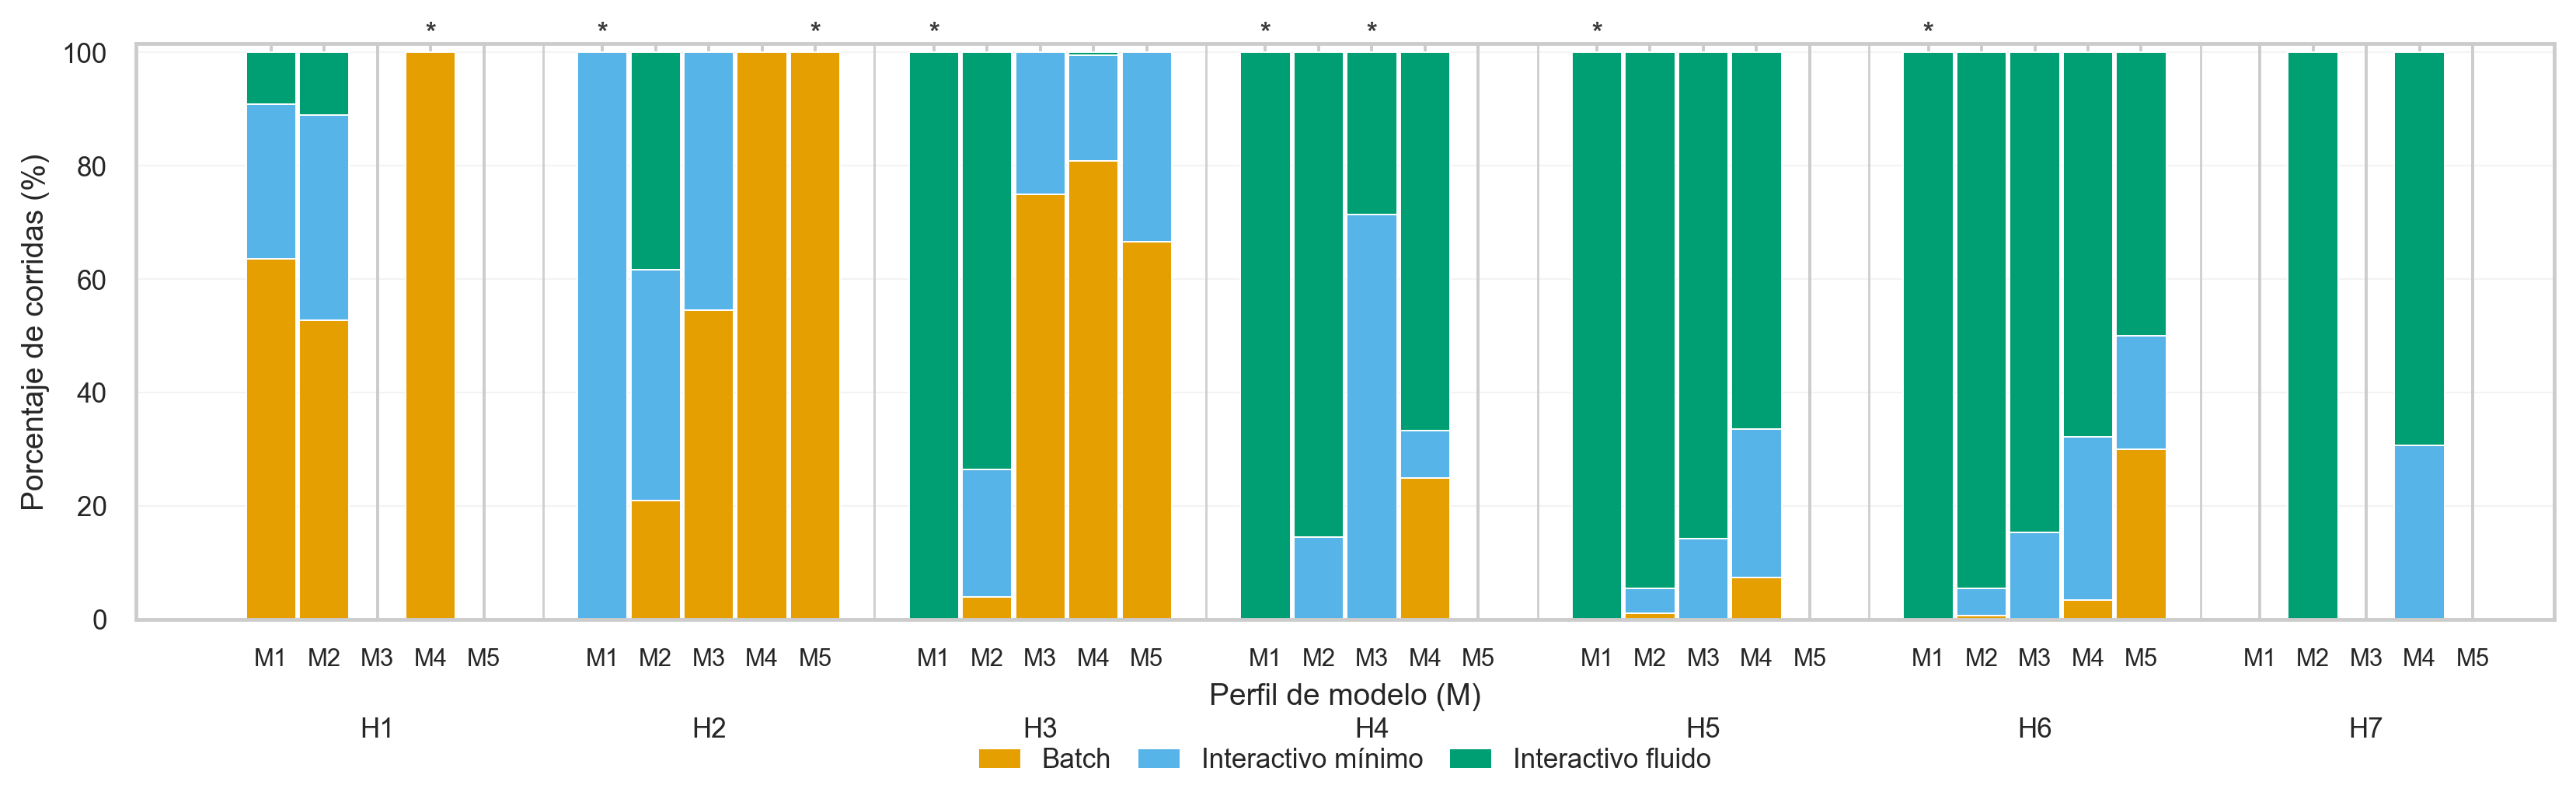

Figura clean PNG: ../reports/figures/fig03_hardware_model_perf_percent_clean.png
Figura clean SVG: ../reports/figures/fig03_hardware_model_perf_percent_clean.svg
Figura clean PDF: ../reports/figures/fig03_hardware_model_perf_percent_clean.pdf


In [18]:
# Variante recomendada (clean) del gráfico porcentual H×M
# Mantiene semántica original: 1 barra por celda H×M, apilada por categoría
# Mejoras de legibilidad: sin tramas, separadores por H, labels M repetidos,
# leyenda abajo, paleta apta daltónicos, márgenes recortados, '*' para n<10.

OUT_FIG_PCT_CLEAN = FIG_DIR / "fig03_hardware_model_perf_percent_clean.png"
OUT_FIG_PCT_CLEAN_SVG = FIG_DIR / "fig03_hardware_model_perf_percent_clean.svg"
OUT_FIG_PCT_CLEAN_PDF = FIG_DIR / "fig03_hardware_model_perf_percent_clean.pdf"

# Paleta colorblind-friendly (Okabe-Ito)
PERF_COLORS_CLEAN = {
    "Batch": "#E69F00",              # naranja
    "Interactivo mínimo": "#56B4E9", # celeste
    "Interactivo fluido": "#009E73", # verde
}

# Datos base (porcentaje por H×M y n por celda)
plot_pct = wide_pct.reindex(index=pd.MultiIndex.from_product([H_ORDER, M_ORDER], names=["H", "M"]), columns=PERF_ORDER).fillna(0)
plot_abs = wide_abs.reindex(index=pd.MultiIndex.from_product([H_ORDER, M_ORDER], names=["H", "M"]), columns=PERF_ORDER).fillna(0)
cell_n = plot_abs.sum(axis=1)

# Geometría: bloques por hardware, 5 barras por bloque (M1..M5)
n_m = len(M_ORDER)
bar_w = 0.195
group_gap = 0.24
block_w = n_m * bar_w

x_positions = {}
xticks = []
xticklabels = []
h_centers = []

for i, h in enumerate(H_ORDER):
    block_start = i * (block_w + group_gap)
    h_centers.append(block_start + (block_w - bar_w) / 2)
    for j, m in enumerate(M_ORDER):
        x = block_start + j * bar_w
        x_positions[(h, m)] = x
        xticks.append(x)
        xticklabels.append(m)

fig, ax = plt.subplots(figsize=(12.0, 4.25), dpi=280)

# Barras apiladas por categoría (sin tramas)
for h in H_ORDER:
    for m in M_ORDER:
        x = x_positions[(h, m)]
        bottom = 0.0
        for cat in PERF_ORDER:
            y = float(plot_pct.loc[(h, m), cat])
            if y > 0:
                ax.bar(
                    x,
                    y,
                    width=bar_w * 0.94,
                    bottom=bottom,
                    color=PERF_COLORS_CLEAN[cat],
                    edgecolor="white",
                    linewidth=0.50,
                )
            bottom += y

        # Marcar baja muestra
        n = float(cell_n.loc[(h, m)])
        if n > 0 and n < LOW_N_THRESHOLD:
            ax.text(x, 100.9, "*", ha="center", va="bottom", fontsize=9, color="#3a3a3a", fontweight="bold")

# Separadores por bloque H
for i in range(1, len(H_ORDER)):
    prev_end = (i - 1) * (block_w + group_gap) + (n_m - 1) * bar_w + bar_w / 2
    next_start = i * (block_w + group_gap) - bar_w / 2
    sep_x = (prev_end + next_start) / 2
    ax.axvline(sep_x, color="#d0d0d0", lw=0.75, zorder=0)

# Ejes y etiquetas (sin título para ahorrar espacio en paper)
ax.set_ylim(0, 101.5)
ax.set_ylabel("Porcentaje de corridas (%)", fontsize=10)
ax.set_xlabel("Perfil de modelo (M)", fontsize=10)

ax.set_xticks(xticks)
ax.set_xticklabels(xticklabels, fontsize=8)
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="y", alpha=0.22, linestyle="-", linewidth=0.55)

# Etiquetas de H centradas por bloque
for xc, h in zip(h_centers, H_ORDER):
    ax.text(xc, -0.17, h, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9)

# Leyenda única abajo en una línea, más compacta
perf_handles = [Patch(facecolor=PERF_COLORS_CLEAN[c], edgecolor="none", label=c) for c in PERF_ORDER]
ax.legend(
    handles=perf_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False,
    fontsize=9,
    handlelength=1.5,
    columnspacing=1.0,
)

# Sin nota interna: mover la aclaración al caption del paper
fig.tight_layout(rect=[0, 0.065, 1, 1])
fig.savefig(OUT_FIG_PCT_CLEAN, bbox_inches="tight", pad_inches=0.02)
fig.savefig(OUT_FIG_PCT_CLEAN_SVG, bbox_inches="tight", pad_inches=0.02)
fig.savefig(OUT_FIG_PCT_CLEAN_PDF, bbox_inches="tight", pad_inches=0.02)
plt.show()
plt.close(fig)

print("Figura clean PNG:", OUT_FIG_PCT_CLEAN)
print("Figura clean SVG:", OUT_FIG_PCT_CLEAN_SVG)
print("Figura clean PDF:", OUT_FIG_PCT_CLEAN_PDF)